In [1]:
import pandas as pd, numpy as np, glob, os
import matplotlib.pyplot as plt

fichiers = sorted(glob.glob("../data/raw/*.parquet"))
print(len(fichiers), "fichiers trouvés")

morceaux = []
for f in fichiers:
    d = pd.read_parquet(f)
    d.columns = d.columns.str.strip()
    # float32 au lieu de float64 : la mémoire est divisée par 2
    cols_num = d.select_dtypes(include="float64").columns
    d[cols_num] = d[cols_num].astype("float32")
    morceaux.append(d)

df = pd.concat(morceaux, ignore_index=True)
del morceaux
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


8 fichiers trouvés
(2313810, 78)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


In [4]:
print(df["Label"].value_counts())

Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [5]:
df["Label"] = (df["Label"].astype(str)
               .str.replace("\ufffd", "-", regex=False)
               .str.strip())
print(df["Label"].value_counts())

Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack - Brute Force         1470
Bot                              1437
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [6]:
df = df.replace([np.inf, -np.inf], np.nan)
print("lignes avec NaN :", df.isna().any(axis=1).sum())
print(df.isna().sum().sort_values(ascending=False).head(5))

lignes avec NaN : 0
Protocol                    0
Flow Duration               0
Total Fwd Packets           0
Total Backward Packets      0
Fwd Packets Length Total    0
dtype: int64


In [7]:
avant = len(df)
df = df.dropna()
print("supprimées (NaN)     :", avant - len(df))

avant = len(df)
df = df.drop_duplicates()
print("supprimées (doublons):", avant - len(df))
print(df.shape)

supprimées (NaN)     : 0
supprimées (doublons): 114597
(2199213, 78)


In [8]:
CLASSE_NORMALE = "Benign"  

df["is_attack"] = (df["Label"] != CLASSE_NORMALE).astype("int8")
print(df["is_attack"].value_counts())
print(df["is_attack"].value_counts(normalize=True).round(3))

is_attack
0    1862721
1     336492
Name: count, dtype: int64
is_attack
0    0.847
1    0.153
Name: proportion, dtype: float64


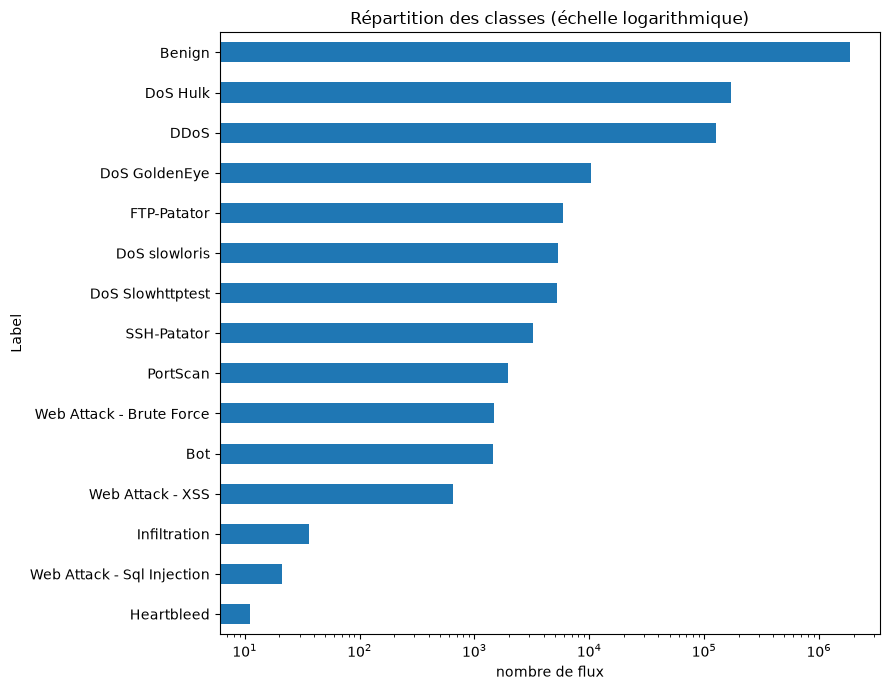

In [9]:
ax = df["Label"].value_counts().sort_values().plot(kind="barh", logx=True, figsize=(9, 7))
ax.set_title("Répartition des classes (échelle logarithmique)")
ax.set_xlabel("nombre de flux")
plt.tight_layout()
os.makedirs("../reports", exist_ok=True)
plt.savefig("../reports/repartition_classes.png", dpi=150)
plt.show()

In [10]:
os.makedirs("../data/processed", exist_ok=True)
df.to_parquet("../data/processed/flows_clean.parquet", index=False)
print("sauvegardé :", df.shape)

sauvegardé : (2199213, 79)
